# CAR PRICE PREDICTION USING MACHINE LEARNING

### BUSINESS UNDERSTANDING

When people buy or sell used cars, deciding on a fair price can be difficult. The price depends on several factors, including:
- Manufacturing year of the car
- Kilometers driven
- Fuel type (Petrol, Diesel, etc.)
- Transmission type (Manual or Automatic)
- Number of previous owners
- Seller or dealer information, depending on the dataset
For example, two cars of the same model may have different prices because one is newer and has fewer kilometers driven.

Machine learning can learn patterns from historical car listings and use them to estimate a reasonable selling price for another car.

#### PROBLEM STATEMENT

The objective of this project is to develop a machine learning regression model that predicts the estimated selling price of a used car based on relevant features such as manufacturing year, kilometers driven, fuel type, transmission, and other available vehicle characteristics. The trained model will be deployed through a Gradio web interface so that users can enter car details and receive a price estimate.

#### PROJECT OBJECTIVES

1. Collect and load a suitable used-car dataset.
2. Understand the dataset's structure, features, and target variable.
3. Perform data cleaning and exploratory data analysis (EDA).
4. Handle missing values and encode categorical features.
5. Select relevant features and split the data into training and testing sets.
6. Train and compare multiple regression models.
7. Evaluate models using MAE, RMSE, and \(R^2\).
8. Save the best model and its preprocessing pipeline.
9. Deploy the model using Gradio.
10. Test the deployed application and prepare the final submission.

#### TYPE OF MACHINE LEARNING PROBLEM

Learning type : Supervised learning

Problem type : Regression

Why regression? Because the output is a numerical value — the estimated price of a car — rather than a category such as spam/not spam.


#### EXPECTED OUTPUT

At the end of this project, a user should be able to enter car details into a simple web application and receive an estimated selling price. We'll use actual test data to measure how accurate the model is rather than assuming it will predict every car correctly.

Important: The prediction is an estimate, not a guaranteed market price.

### Dataset Collection and Project Setup

For this project, we'll use the beginner-friendly CarDekho used-car dataset, which contains information about used cars in India. A commonly used version has fields such as year, selling price, kilometers driven, fuel type, seller type, transmission, and previous owners.

#### Installing Required Libraries

In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib gradio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


These libraries will be used for the following purposes:
Library	Purpose
Pandas	Load and manipulate data
NumPy	Numerical operations
Matplotlib	Create charts
Seaborn	Statistical visualizations
Scikit-learn	Preprocessing, model training, and evaluation
Joblib	Save and load the trained model
Gradio	Build the interactive web application

Gradio supports building interfaces directly in Jupyter Notebook, so you can test your application without building a separate frontend.

#### Importing Required Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


#### Loading The Dataset

In [5]:
df = pd.read_csv(r"CAR DETAILS FROM CAR DEKHO.csv")

print("Dataset Loaded Successfully!")
print("Dataset shape:",df.shape)

df.head()

Dataset Loaded Successfully!
Dataset shape: (4340, 8)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


### Data Understanding and EDA

EDA helps us understand our data before training a machine learning model. We'll investigate the dataset's structure, data quality, and relationships between car features and selling prices.

In [6]:
# Dimenssions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 4340
Number of columns: 8


In [7]:
#Displaying the first and last records

df.head() # first 5 records

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [8]:
df.tail() # last 5 records

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,Diesel,Individual,Manual,Second Owner
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4337,Maruti 800 AC BSIII,2009,110000,83000,Petrol,Individual,Manual,Second Owner
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,Diesel,Individual,Manual,First Owner
4339,Renault KWID RXT,2016,225000,40000,Petrol,Individual,Manual,First Owner


#### Inspecting column names and data types

In [9]:
# Display column information

print("Column names:")
print(df.columns.tolist())


Column names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']


In [10]:
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 271.4 KB


#### Checking missing values

In [11]:
# Count missing values
missing_count = df.isnull().sum()
missing_count

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

#### Checking duplicate records

In [12]:
# Count duplicates

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 763


#### numerical summaries

In [13]:
# Descriptive statistics
df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


This displays the count, mean, standard deviation, minimum, quartiles, and maximum for numerical columns.

For example:
- mean tells us the average.
- 50% represents the median.
- min and max reveal the range.
- A large gap between the mean and median can indicate a skewed distribution or extreme values.

#### Summarizing categorical column

In [14]:
df.describe(include="object")

C:\Users\kotap\AppData\Local\Temp\ipykernel_4984\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,name,fuel,seller_type,transmission,owner
count,4340,4340,4340,4340,4340
unique,1491,5,3,2,5
top,Maruti Swift Dzire VDI,Diesel,Individual,Manual,First Owner
freq,69,2153,3244,3892,2832


This helps us identify common categories, such as the most frequent fuel type or transmission type.

#### Identifying the target variable

In [15]:
# Display possible price-related columns

print([
    col for col in df.columns
    if "price" in col.lower()
])

['selling_price']


##### Don't rename or delete columns yet. First, identify the correct target column in your dataset.

#### Data Visuvalization

#### Understanding the Data Quality

In [16]:
#Check duplicate rows

print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 763


In [17]:
#If duplicates exist, inspect them before removing anything

df[df.duplicated(keep=False)].head(10)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner
5,Maruti Alto LX BSIII,2007,140000,125000,Petrol,Individual,Manual,First Owner
6,Hyundai Xcent 1.2 Kappa S,2016,550000,25000,Petrol,Individual,Manual,First Owner
7,Tata Indigo Grand Petrol,2014,240000,60000,Petrol,Individual,Manual,Second Owner
8,Hyundai Creta 1.6 VTVT S,2015,850000,25000,Petrol,Individual,Manual,First Owner
9,Maruti Celerio Green VXI,2017,365000,78000,CNG,Individual,Manual,First Owner


In [18]:
#Get numerical summaries

display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
year,4340.0,2013.090783,4.215344,1992.0,2011.00,2014.0,2016.0,2020.0
selling_price,4340.0,504127.311751,578548.736139,20000.0,208749.75,350000.0,600000.0,8900000.0
km_driven,4340.0,66215.777419,46644.102194,1.0,35000.00,60000.0,90000.0,806599.0


In [19]:
# Inspection of categories

for col in ["fuel", "seller_type", "transmission", "owner"]:
    print(f"\n{col}:")
    print(df[col].value_counts())


fuel:
fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64

seller_type:
seller_type
Individual          3244
Dealer               994
Trustmark Dealer     102
Name: count, dtype: int64

transmission:
transmission
Manual       3892
Automatic     448
Name: count, dtype: int64

owner:
owner
First Owner             2832
Second Owner            1106
Third Owner              304
Fourth & Above Owner      81
Test Drive Car            17
Name: count, dtype: int64


-  This tells us how many cars belong to each category.

In [20]:
#### Create visualizations

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

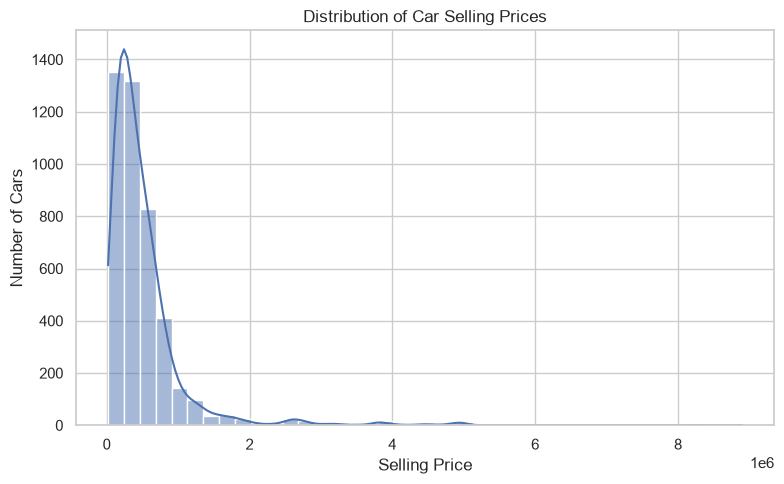

In [21]:
# Chart 1 — Selling price distribution

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="selling_price", bins=40, kde=True)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

- This chart shows whether prices are concentrated in the lower price range or spread across a wide range. A long right tail often indicates a few expensive cars.

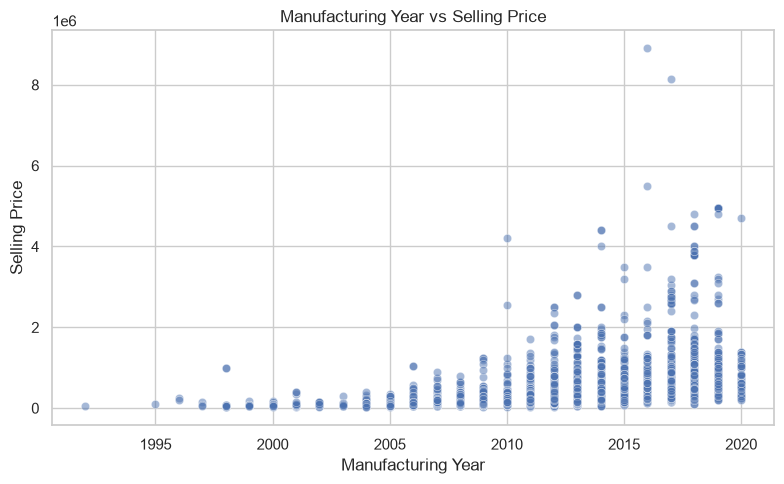

In [22]:
# Chart 2 — Manufacturing year vs selling price

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="year",
    y="selling_price",
    alpha=0.5
)

plt.title("Manufacturing Year vs Selling Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()

- Look for whether newer cars tend to have higher prices. The relationship may not be perfectly linear because brand, condition, and model also influence price.

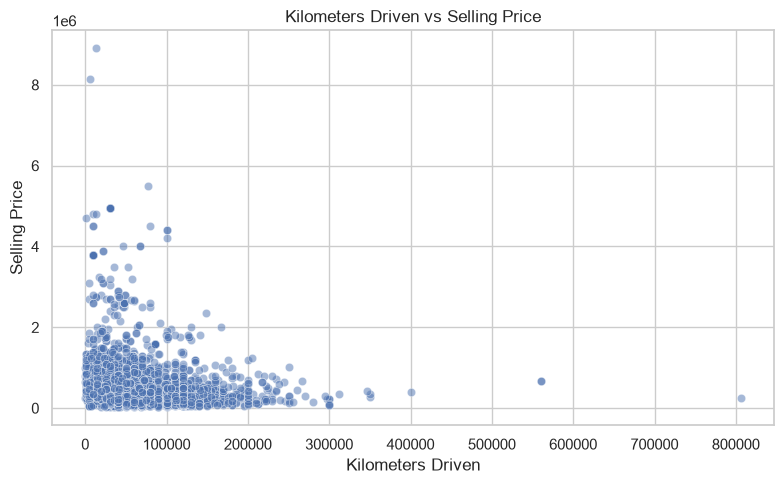

In [23]:
# Chart 3 — Kilometers driven vs selling price

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="km_driven",
    y="selling_price",
    alpha=0.5
)

plt.title("Kilometers Driven vs Selling Price")
plt.xlabel("Kilometers Driven")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()

- Check whether selling prices generally decrease as kilometers driven increase. Outliers are worth investigating rather than automatically deleting.

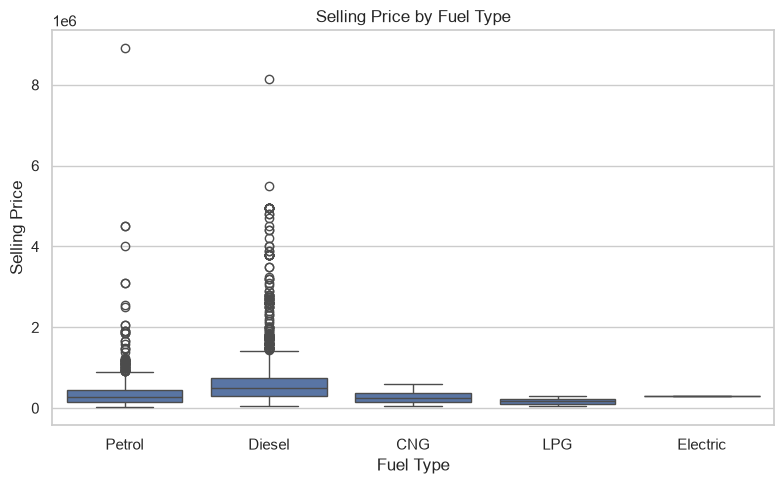

In [24]:
# Chart 4 — Selling price by fuel type

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="fuel",
    y="selling_price"
)

plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()

- Compare the median prices and spread across fuel types. Remember that differences may also reflect differences in car models and years.

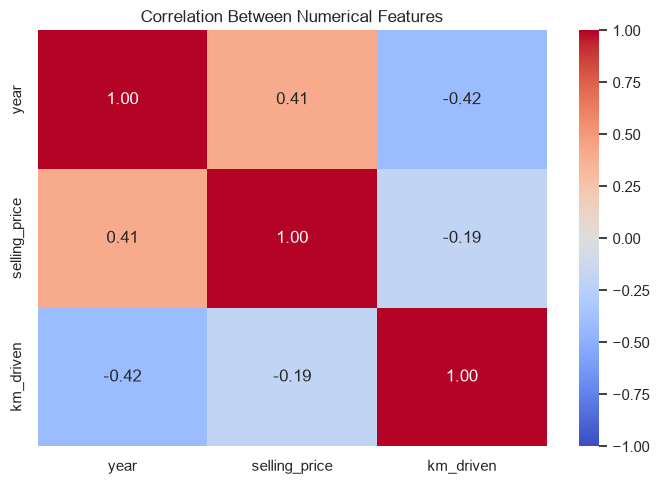

In [25]:
# Chart 5 — Correlation between numerical features

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(7, 5))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

- Correlation ranges from -1 to +1. Values near +1 indicate a positive linear relationship; values near -1 indicate a negative one. Correlation does not prove causation.

##### Duplicate records
- found 763 duplicate rows

-  Before removing them, let's inspect what is duplicated. In this dataset, multiple listings might describe similar cars, but exact repeated rows may be redundant.

In [26]:
# Inspect duplicate records
duplicates = df[df.duplicated(keep=False)]

print("Rows involved in duplicate groups:", len(duplicates))

display(duplicates.head(10))

Rows involved in duplicate groups: 1289


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner
5,Maruti Alto LX BSIII,2007,140000,125000,Petrol,Individual,Manual,First Owner
6,Hyundai Xcent 1.2 Kappa S,2016,550000,25000,Petrol,Individual,Manual,First Owner
7,Tata Indigo Grand Petrol,2014,240000,60000,Petrol,Individual,Manual,Second Owner
8,Hyundai Creta 1.6 VTVT S,2015,850000,25000,Petrol,Individual,Manual,First Owner
9,Maruti Celerio Green VXI,2017,365000,78000,CNG,Individual,Manual,First Owner


-  If these are exact repeated records, we can keep one copy of each:

In [27]:
# Remove exact duplicate rows
df = df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (3577, 8)
Remaining duplicate rows: 0


- Why remove duplicates? Exact duplicate rows can cause repeated observations to receive extra weight during model training. However, only remove them if they are genuine duplicate records for your project dataset.

In [28]:
# Check unusual values

print("Year range:", df["year"].min(), "-", df["year"].max())
print("Selling price range:",
      df["selling_price"].min(), "-",
      df["selling_price"].max())
print("Kilometers driven range:",
      df["km_driven"].min(), "-",
      df["km_driven"].max())

print("\nCars with more than 300,000 km driven:")
display(df[df["km_driven"] > 300000])

Year range: 1992 - 2020
Selling price range: 20000 - 8900000
Kilometers driven range: 1 - 806599

Cars with more than 300,000 km driven:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
69,Chevrolet Tavera Neo LS B3 - 7(C) seats BSIII,2010,280000,350000,Diesel,Individual,Manual,Second Owner
525,Maruti SX4 S Cross DDiS 320 Delta,2016,665000,560000,Diesel,Dealer,Manual,First Owner
1243,Maruti Swift VXI BSIII,2009,250000,806599,Petrol,Dealer,Manual,First Owner
1674,Volkswagen Jetta 2.0 TDI Comfortline,2011,350000,312000,Diesel,Individual,Manual,Third Owner
2394,Toyota Innova 2.5 V Diesel 8-seater,2009,350000,350000,Diesel,Individual,Manual,First Owner
3679,Toyota Innova 2.5 G (Diesel) 7 Seater BS IV,2006,400000,400000,Diesel,Individual,Manual,Third Owner
3718,Toyota Innova 2.5 GX 8 STR BSIV,2009,420000,347089,Diesel,Dealer,Manual,First Owner


-  This helps us identify extreme values for review. A value is not automatically an error simply because it is unusually high.

##### understand categorical features
-  different categories and their counts

In [29]:
for col in ["fuel", "seller_type", "transmission", "owner"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- fuel ---
fuel
Diesel      1800
Petrol      1717
CNG           37
LPG           22
Electric       1
Name: count, dtype: int64

--- seller_type ---
seller_type
Individual          2832
Dealer               712
Trustmark Dealer      33
Name: count, dtype: int64

--- transmission ---
transmission
Manual       3265
Automatic     312
Name: count, dtype: int64

--- owner ---
owner
First Owner             2218
Second Owner             978
Third Owner              289
Fourth & Above Owner      75
Test Drive Car            17
Name: count, dtype: int64


These findings mean for machine learning?
- We should retain fuel, seller_type, transmission, and owner as categorical features.
- We should use encoding to convert categorical values into numerical representations.
- The single electric-car record is too little data to learn a reliable electric-car pricing pattern. We'll keep the category initially and use an encoding strategy that handles rare or unseen categories safely.
- We'll investigate the name column. Car model information may be valuable, but there are many distinct model names, so using it directly could create a high-dimensional feature set.
One more important point: removing duplicates reduces repeated records, but it does not guarantee that every remaining car listing is unique in the real world.

#### Final EDA checks

- Before training a model, let's examine the car names and the unusually high mileage values.

In [30]:
# Check how many different car names exist

print("Unique car names:", df["name"].nunique())
print("\nMost common car names:")
print(df["name"].value_counts().head(10))

Unique car names: 1491

Most common car names:
name
Maruti Swift Dzire VDI      54
Maruti Alto 800 LXI         48
Maruti Alto LXi             42
Maruti Alto LX              30
Hyundai EON Era Plus        28
Maruti Swift VDI BSIV       28
Maruti Wagon R VXI BS IV    26
Maruti Swift VDI            23
Maruti Wagon R LXI Minor    21
Maruti 800 AC               20
Name: count, dtype: int64


- This helps us decide how to use name. For our first model, we'll extract the first word as a basic brand feature rather than encoding every complete car name separately.

In [31]:
# Check unusually high kilometers driven

display(
    df[df["km_driven"] > 300000]
    .sort_values("km_driven", ascending=False)
    .head(10)
)

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
1243,Maruti Swift VXI BSIII,2009,250000,806599,Petrol,Dealer,Manual,First Owner
525,Maruti SX4 S Cross DDiS 320 Delta,2016,665000,560000,Diesel,Dealer,Manual,First Owner
3679,Toyota Innova 2.5 G (Diesel) 7 Seater BS IV,2006,400000,400000,Diesel,Individual,Manual,Third Owner
69,Chevrolet Tavera Neo LS B3 - 7(C) seats BSIII,2010,280000,350000,Diesel,Individual,Manual,Second Owner
2394,Toyota Innova 2.5 V Diesel 8-seater,2009,350000,350000,Diesel,Individual,Manual,First Owner
3718,Toyota Innova 2.5 GX 8 STR BSIV,2009,420000,347089,Diesel,Dealer,Manual,First Owner
1674,Volkswagen Jetta 2.0 TDI Comfortline,2011,350000,312000,Diesel,Individual,Manual,Third Owner


- Review the records. Do not remove them automatically; unusually high mileage may be genuine.

### Data preprocessing, feature selection, and train-test split

#### Create the brand feature and separate X and y

In [32]:
# Work on a copy of the cleaned dataset
model_df = df.copy()

# Extract the first word of the car name as a basic brand feature
model_df["brand"] = (
    model_df["name"]
    .str.strip()
    .str.split()
    .str[0]
)

# Define input features
feature_columns = [
    "brand",
    "year",
    "km_driven",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

X = model_df[feature_columns].copy()
y = model_df["selling_price"].copy()

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

display(X.head())
display(y.head())

Feature dataset shape: (3577, 7)
Target dataset shape: (3577,)


,brand,year,km_driven,fuel,seller_type,transmission,owner
0,Maruti,2007,70000,Petrol,Individual,Manual,First Owner
1,Maruti,2007,50000,Petrol,Individual,Manual,First Owner
2,Hyundai,2012,100000,Diesel,Individual,Manual,First Owner
3,Datsun,2017,46000,Petrol,Individual,Manual,First Owner
4,Honda,2014,141000,Diesel,Individual,Manual,Second Owner


0     60000
1    135000
2    600000
3    250000
4    450000
Name: selling_price, dtype: int64

Understanding the terms:
- X contains the information the model uses to make predictions.
- y contains the correct selling prices the model learns to predict.
- brand is a simplified feature extracted from the car name.

#### Split the data into training and testing sets

We'll use an 80/20 split.
- 80% training data: Used to train the model.
- 20% testing data: Kept separate to evaluate the model on unseen records.

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (2861, 7)
Testing features: (716, 7)
Training targets: (2861,)
Testing targets: (716,)


- The random_state=42 setting makes the split reproducible, so you can obtain the same split when you rerun the notebook with the same data.

#### Prepare the preprocessing pipeline

Machine learning models generally require numerical inputs. We'll use:
- SimpleImputer to handle any missing values if they appear.
- OneHotEncoder to convert categorical features into numerical columns.
- StandardScaler for numerical features when needed; tree-based models generally do not require scaling.
We will create the preprocessing pipeline now and fit it only on the training data later. This avoids data leakage from the test set.

In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_features = ["year", "km_driven"]

categorical_features = [
    "brand",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


- handle_unknown="ignore" is especially useful for deployment: the application might receive a category that was not present in the training data.

### 5 — Model Building, Evaluation, and Selection

In [35]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

print("Models imported successfully!")

Models imported successfully!


#### Build complete model pipelines

- Each pipeline will apply preprocessing first and then train the model. This keeps the feature transformations consistent between training and deployment.

In [36]:
from sklearn.pipeline import Pipeline

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42,
        min_samples_leaf=5
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

pipelines = {}

for name, model in models.items():
    pipelines[name] = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

print("All model pipelines created successfully!")

All model pipelines created successfully!


##### Why use a pipeline?

- A pipeline combines preprocessing and prediction into a single object. Later, when a user enters car details in Gradio, the same preprocessing steps will automatically be applied.

#### Train the models

In [37]:
for name, pipeline in pipelines.items():
    print(f"Training {name}...")
    pipeline.fit(X_train, y_train)
    print(f"{name} trained successfully!\n")

Training Linear Regression...
Linear Regression trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training Random Forest...
Random Forest trained successfully!



#### Evaluate the models

Metric	  -   Meaning  -  	Better result

MAE	      -  Average absolute prediction error	-   Lower

RMSE	-   Penalizes large errors more heavily	 -  Lower

R²      - 	How much variation in prices the model explains relative to a mean baseline	Generally    - higher

In [38]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import numpy as np

results = []

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results).sort_values(
    by="MAE",
    ascending=True
)

display(results_df.round(3))

,Model,MAE,RMSE,R2 Score
2,Random Forest,156498.167,359335.065,0.599
1,Decision Tree,185480.049,398804.803,0.506
0,Linear Regression,206368.402,431734.103,0.421


#### Visualize the comparison

Let's compare MAE across models.

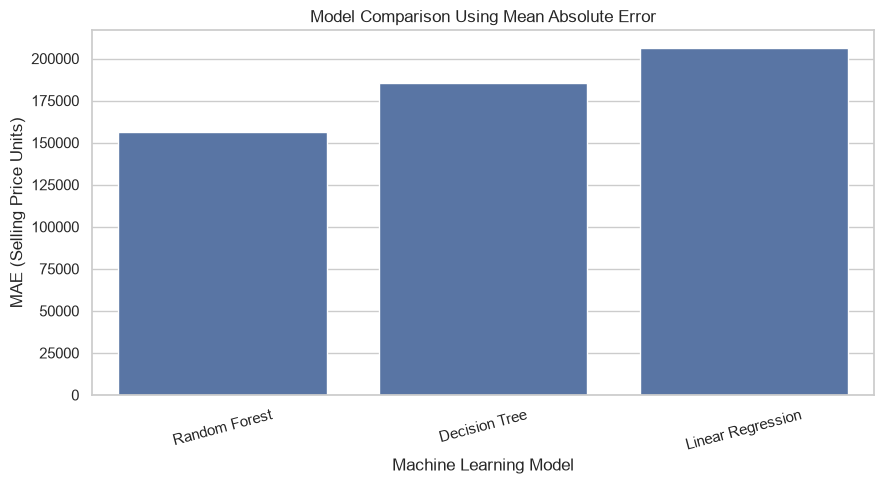

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE"
)

plt.title("Model Comparison Using Mean Absolute Error")
plt.xlabel("Machine Learning Model")
plt.ylabel("MAE (Selling Price Units)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

#### Selectingthe best model

In [40]:
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = pipelines[best_model_name]

print("Best model based on test MAE:", best_model_name)
print(
    "Test MAE:",
    round(results_df.iloc[0]["MAE"], 2)
)
print(
    "Test RMSE:",
    round(results_df.iloc[0]["RMSE"], 2)
)
print(
    "Test R2 Score:",
    round(results_df.iloc[0]["R2 Score"], 4)
)

Best model based on test MAE: Random Forest
Test MAE: 156498.17
Test RMSE: 359335.07
Test R2 Score: 0.5992


### Actual vs predicted prices

### Generate predictions

In [41]:
# Use the selected best model
y_pred = best_pipeline.predict(X_test)

comparison_df = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Predicted_Price": y_pred
})

comparison_df["Absolute_Error"] = abs(
    comparison_df["Actual_Price"]
    - comparison_df["Predicted_Price"]
)

display(comparison_df.head(10).round(2))

,Actual_Price,Predicted_Price,Absolute_Error
0,270000,571073.00,301073.00
1,525000,456701.50,68298.50
2,990000,1227215.26,237215.26
3,3800000,2446542.56,1353457.44
4,229999,235102.30,5103.30
5,325000,316734.13,8265.87
6,210000,173812.46,36187.54
7,500000,679983.07,179983.07
8,790000,908461.10,118461.10
9,360000,535417.55,175417.55


#### Plot Actual vs Predicted Prices

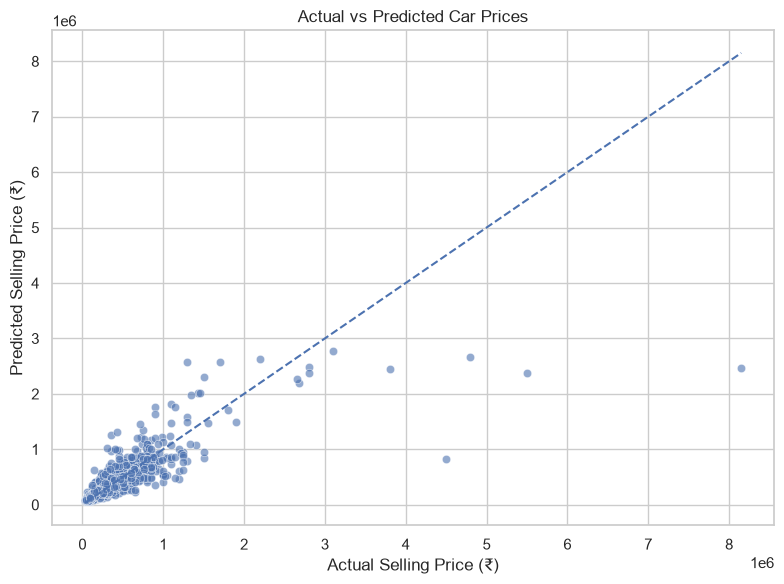

In [42]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.6
)

min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.title("Actual vs Predicted Car Prices")
plt.xlabel("Actual Selling Price (₹)")
plt.ylabel("Predicted Selling Price (₹)")
plt.tight_layout()
plt.show()

Points close to the diagonal line represent more accurate predictions. Points farther away indicate larger prediction errors.

#### Find the largest prediction errors

In [43]:
display(
    comparison_df
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
)

,Actual_Price,Predicted_Price,Absolute_Error
187,8150000,2.460061e+06,5.689939e+06
484,4500000,8.266037e+05,3.673396e+06
445,5500000,2.370953e+06,3.129047e+06
136,4800000,2.660194e+06,2.139806e+06
3,3800000,2.446543e+06,1.353457e+06
657,1300000,2.582313e+06,1.282313e+06
418,350000,1.258356e+06,9.083564e+05
528,426000,1.311889e+06,8.858889e+05
693,1700000,2.579627e+06,8.796266e+05
338,900000,1.771929e+06,8.719294e+05


- This helps us identify where the model struggles, particularly for expensive cars or unusual records.

### Saving the Trained model

- Once you've checked the predictions, save the entire pipeline. This includes both preprocessing and the Random Forest model.

In [44]:
import os
import joblib

model_path = "../ML_Project_Own/car_price_model.pkl"

joblib.dump(best_pipeline, model_path)

print("Model saved successfully!")
print("Saved at:", model_path)

Model saved successfully!
Saved at: ../ML_Project_Own/car_price_model.pkl


#### To verify that the saved model works:

In [45]:
loaded_model = joblib.load(model_path)

sample_predictions = loaded_model.predict(X_test.head(5))

print("Predictions from the saved model:")
print(sample_predictions)

Predictions from the saved model:
[ 571073.00237956  456701.50303571 1227215.25966667 2446542.5555
  235102.29867063]


-  The loaded model should produce the same predictions as best_pipeline for the same inputs, assuming the same environment and data.

### Building the Gradio application

In [46]:
import gradio as gr
import pandas as pd
import joblib
import os

model_path = "../models/car_price_model.pkl"

if os.path.exists(model_path):
    model = joblib.load(model_path)
    print("Saved model loaded successfully!")
else:
    model = best_pipeline
    print("Using the trained best_pipeline model.")

Saved model loaded successfully!


In [47]:
def predict_car_price(
    brand,
    year,
    km_driven,
    fuel,
    seller_type,
    transmission,
    owner
):
    input_data = pd.DataFrame([{
        "brand": brand.strip(),
        "year": int(year),
        "km_driven": int(km_driven),
        "fuel": fuel,
        "seller_type": seller_type,
        "transmission": transmission,
        "owner": owner
    }])

    predicted_price = model.predict(input_data)[0]

    return f"Estimated Car Selling Price: ₹{predicted_price:,.0f}"

In [48]:
car_price_app = gr.Interface(
    fn=predict_car_price,

    inputs=[
        gr.Textbox(
            label="Car Brand",
            placeholder="Enter brand, e.g. Maruti",
            value="Maruti"
        ),

        gr.Number(
            label="Manufacturing Year",
            value=2018,
            precision=0
        ),

        gr.Number(
            label="Kilometers Driven",
            value=50000,
            precision=0
        ),

        gr.Dropdown(
            choices=["Diesel", "Petrol", "CNG", "LPG", "Electric"],
            label="Fuel Type",
            value="Petrol"
        ),

        gr.Dropdown(
            choices=["Individual", "Dealer", "Trustmark Dealer"],
            label="Seller Type",
            value="Individual"
        ),

        gr.Dropdown(
            choices=["Manual", "Automatic"],
            label="Transmission",
            value="Manual"
        ),

        gr.Dropdown(
            choices=[
                "First Owner",
                "Second Owner",
                "Third Owner",
                "Fourth & Above Owner",
                "Test Drive Car"
            ],
            label="Owner Type",
            value="First Owner"
        )
    ],

    outputs=gr.Textbox(label="Predicted Selling Price"),

    title="🚗 Car Price Prediction Using Machine Learning",

    description=(
        "Enter the details of a used car to estimate its selling price. "
        "The prediction is an estimate, not a guaranteed market value."
    ),

    examples=[
        ["Maruti", 2018, 50000, "Petrol", "Individual", "Manual", "First Owner"],
        ["Hyundai", 2017, 65000, "Diesel", "Dealer", "Manual", "Second Owner"],
        ["Toyota", 2019, 30000, "Diesel", "Dealer", "Automatic", "First Owner"]
    ]
)

print("Gradio interface created successfully!")

Gradio interface created successfully!


In [49]:
car_price_app.launch(share=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://4ffa00d6e2a449b73c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
